In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, LeaveOneOut, KFold, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
df = pd.read_csv("/content/car_price_dataset.csv")
print(f"Dataset shape: {df.shape}")

Dataset shape: (10000, 10)


In [ ]:
df

,Brand,Model,Year,Engine_Size,Fuel_Type,Transmission,Mileage,Doors,Owner_Count,Price
0,Kia,Rio,2020,4.2,Diesel,Manual,289944,3,5,8501
1,Chevrolet,Malibu,2012,2.0,Hybrid,Automatic,5356,2,3,12092
2,Mercedes,GLA,2020,4.2,Diesel,Automatic,231440,4,2,11171
3,Audi,Q5,2023,2.0,Electric,Manual,160971,2,1,11780
4,Volkswagen,Golf,2003,2.6,Hybrid,Semi-Automatic,286618,3,3,2867
...,...,...,...,...,...,...,...,...,...,...
9995,Kia,Optima,2004,3.7,Diesel,Semi-Automatic,5794,2,4,8884
9996,Chevrolet,Impala,2002,1.4,Electric,Automatic,168000,2,1,6240
9997,BMW,3 Series,2010,3.0,Petrol,Automatic,86664,5,1,9866
9998,Ford,Explorer,2002,1.4,Hybrid,Automatic,225772,4,1,4084


In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         10000 non-null  object 
 1   Model         10000 non-null  object 
 2   Year          10000 non-null  int64  
 3   Engine_Size   10000 non-null  float64
 4   Fuel_Type     10000 non-null  object 
 5   Transmission  10000 non-null  object 
 6   Mileage       10000 non-null  int64  
 7   Doors         10000 non-null  int64  
 8   Owner_Count   10000 non-null  int64  
 9   Price         10000 non-null  int64  
dtypes: float64(1), int64(5), object(4)
memory usage: 781.4+ KB


,Year,Engine_Size,Mileage,Doors,Owner_Count,Price
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,2011.543700,3.000560,149239.111800,3.497100,2.991100,8852.96440
std,6.897699,1.149324,86322.348957,1.110097,1.422682,3112.59681
min,2000.000000,1.000000,25.000000,2.000000,1.000000,2000.00000
25%,2006.000000,2.000000,74649.250000,3.000000,2.000000,6646.00000
50%,2012.000000,3.000000,149587.000000,3.000000,3.000000,8858.50000
75%,2017.000000,4.000000,223577.500000,4.000000,4.000000,11086.50000
max,2023.000000,5.000000,299947.000000,5.000000,5.000000,18301.00000


In [ ]:
columns_list = df.columns.tolist()
columns_list

['Brand',
 'Model',
 'Year',
 'Engine_Size',
 'Fuel_Type',
 'Transmission',
 'Mileage',
 'Doors',
 'Owner_Count',
 'Price']

In [ ]:
features = ['Brand',
 'Model',
 'Year',
 'Engine_Size',
 'Fuel_Type',
 'Transmission',
 'Mileage',
 'Doors',
 'Owner_Count']
x = df [features]
y = df ['Price']

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(x, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)


numeric_features = ['Year', 'Engine_Size', 'Mileage', 'Doors', 'Owner_Count']
categorical_features = ['Brand', 'Model', 'Fuel_Type', 'Transmission']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_val_preprocessed = preprocessor.transform(X_val)
best_k = None
best_score = float('inf')

for k in range(3, 15):
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train_preprocessed, y_train)
    val_preds = knn.predict(X_val_preprocessed)
    mse = mean_squared_error(y_val, val_preds)
    print(mse)
    if mse < best_score:
        best_score = mse
        best_k = k

print(f"Best k: {best_k} with validation MSE: {best_score:.2f}")

X_test_preprocessed = preprocessor.transform(X_test)
final_knn = KNeighborsRegressor(n_neighbors=best_k)
final_knn.fit(X_train_preprocessed, y_train)

test_preds = final_knn.predict(X_test_preprocessed)
test_mse = mean_squared_error(y_test, test_preds)

print(f"Final Test MSE with k={best_k}: {test_mse:.2f}")

1550137.2447777777
1362278.67159375
1230590.47438
1136427.439638889
1083963.5965714285
1038050.198
1005134.1427530863
960186.5433299999
932023.7095867769
914776.1618368056
898121.5470236687
870315.2499234693
Best k: 14 with validation MSE: 870315.25
Final Test MSE with k=14: 908377.09


First 5 rows of the dataset:
        Brand   Model  Year  Engine_Size Fuel_Type    Transmission  Mileage  \
0         Kia     Rio  2020          4.2    Diesel          Manual   289944   
1   Chevrolet  Malibu  2012          2.0    Hybrid       Automatic     5356   
2    Mercedes     GLA  2020          4.2    Diesel       Automatic   231440   
3        Audi      Q5  2023          2.0  Electric          Manual   160971   
4  Volkswagen    Golf  2003          2.6    Hybrid  Semi-Automatic   286618   

   Doors  Owner_Count  Price  
0      3            5   8501  
1      2            3  12092  
2      4            2  11171  
3      2            1  11780  
4      3            3   2867  

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         10000 non-null  object 
 1   Model         10000 non-null  object 
 2   Yea

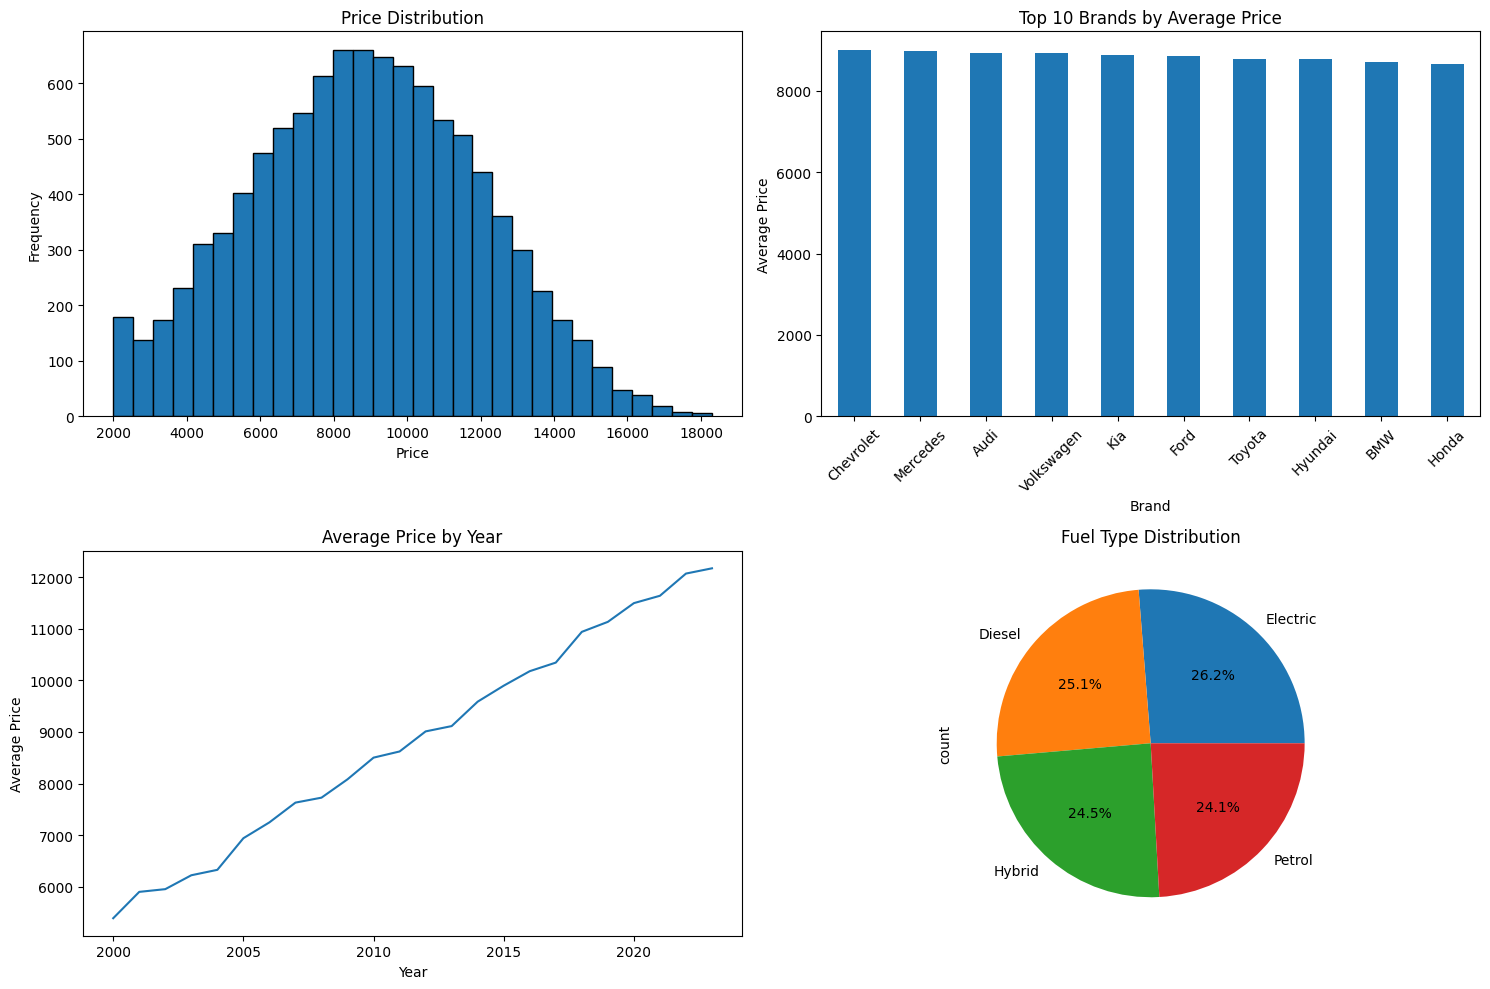


Correlation matrix:
                 Year  Engine_Size   Mileage     Doors  Owner_Count     Price
Year         1.000000    -0.001306 -0.002476  0.014867     0.000116  0.663036
Engine_Size -0.001306     1.000000  0.015135 -0.009844     0.007122  0.357403
Mileage     -0.002476     0.015135  1.000000  0.007879     0.006287 -0.551227
Doors        0.014867    -0.009844  0.007879  1.000000    -0.005431  0.000511
Owner_Count  0.000116     0.007122  0.006287 -0.005431     1.000000  0.002656
Price        0.663036     0.357403 -0.551227  0.000511     0.002656  1.000000


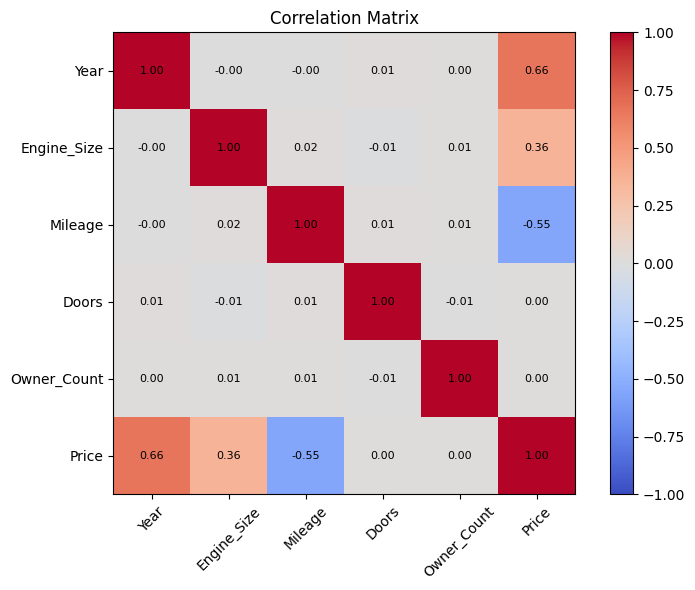


Average price difference between automatic and manual transmission: $99.16

Most expensive car:
Brand              Toyota
Model             Corolla
Year                 2021
Engine_Size           4.7
Fuel_Type        Electric
Transmission    Automatic
Mileage             14924
Doors                   5
Owner_Count             3
Price               18301
Name: 1100, dtype: object

Least expensive car:
Brand              BMW
Model               X5
Year              2002
Engine_Size        2.9
Fuel_Type       Petrol
Transmission    Manual
Mileage         296864
Doors                4
Owner_Count          2
Price             2000
Name: 232, dtype: object

Cleaned data saved to 'cleaned_car_price_data.csv'


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('/content/car_price_dataset.csv')

# 1. Data Exploration
print("First 5 rows of the dataset:")
print(df.head())
print("\nDataset information:")
print(df.info())
print("\nSummary statistics:")
print(df.describe())

# 2. Data Cleaning
# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Remove duplicates if any
df = df.drop_duplicates()
print(f"\nShape after removing duplicates: {df.shape}")

# 3. Data Analysis
# Average price by brand
avg_price_by_brand = df.groupby('Brand')['Price'].mean().sort_values(ascending=False)
print("\nAverage price by brand:")
print(avg_price_by_brand)

# Most common fuel type
most_common_fuel = df['Fuel_Type'].value_counts().idxmax()
print(f"\nMost common fuel type: {most_common_fuel}")

# Price distribution by transmission type
avg_price_by_transmission = df.groupby('Transmission')['Price'].mean()
print("\nAverage price by transmission type:")
print(avg_price_by_transmission)

# 4. Visualization
plt.figure(figsize=(15, 10))

# Price distribution
plt.subplot(2, 2, 1)
df['Price'].plot(kind='hist', bins=30, edgecolor='black')
plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')

# Average price by brand (top 10)
plt.subplot(2, 2, 2)
avg_price_by_brand.head(10).plot(kind='bar')
plt.title('Top 10 Brands by Average Price')
plt.xlabel('Brand')
plt.ylabel('Average Price')
plt.xticks(rotation=45)

# Price by year
plt.subplot(2, 2, 3)
df.groupby('Year')['Price'].mean().plot()
plt.title('Average Price by Year')
plt.xlabel('Year')
plt.ylabel('Average Price')

# Fuel type distribution
plt.subplot(2, 2, 4)
df['Fuel_Type'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Fuel Type Distribution')

plt.tight_layout()
plt.show()

# 5. Correlation Analysis
# Select numerical columns for correlation
numerical_cols = ['Year', 'Engine_Size', 'Mileage', 'Doors', 'Owner_Count', 'Price']
correlation_matrix = df[numerical_cols].corr()

print("\nCorrelation matrix:")
print(correlation_matrix)

# Calculate correlation matrix
correlation_matrix = df[numerical_cols].corr()

# Fill NaN values with 0 (occurs when there's no variation in a column)
correlation_matrix = correlation_matrix.fillna(0)

# Ensure all values are finite (replace inf/-inf if any)
correlation_matrix = correlation_matrix.replace([np.inf, -np.inf], 0)

# Visualize correlation matrix
plt.figure(figsize=(8, 6))

# Use imshow instead of matshow for better control
plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)

# Add colorbar
plt.colorbar()

# Set ticks and labels
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)

# Add values to each cell
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}",
                 ha="center", va="center", color="black", fontsize=8)

plt.title('Correlation Matrix')
plt.tight_layout()  # Prevent label cutoff
plt.show()

# 6. Additional Analysis
# Price difference between automatic and manual transmission
auto_manual_diff = df.groupby('Transmission')['Price'].mean().diff().abs().iloc[-1]
print(f"\nAverage price difference between automatic and manual transmission: ${auto_manual_diff:.2f}")

# Most expensive and least expensive cars
most_expensive = df.loc[df['Price'].idxmax()]
least_expensive = df.loc[df['Price'].idxmin()]
print("\nMost expensive car:")
print(most_expensive)
print("\nLeast expensive car:")
print(least_expensive)

# 7. Save cleaned data
df.to_csv('cleaned_car_price_data.csv', index=False)
print("\nCleaned data saved to 'cleaned_car_price_data.csv'")